In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

import joblib
import os

pd.set_option("display.max_columns", None)

In [4]:
df = pd.read_csv("../data/processed/lifetwin_clean_dataset.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 20)


,user_id,record_date,age_group,day_of_week,sleep_hours,sleep_quality,wake_time_consistency,study_work_hours,focus_sessions,screen_time_hours,social_media_hours,notification_interruptions,exercise_minutes,step_count,stress_level,mood_score,energy_level,caffeine_intake,break_minutes,productivity_score
0,U094,2026-05-13,23-27,Wednesday,3.00,4.5,5.4,10.58,0.9,9.88,4.48,12.0,0.0,3776.0,5.2,3.2,1.0,2.2,10.0,24.7
1,U151,2026-07-14,18-22,Tuesday,6.83,5.5,6.8,3.31,4.0,10.61,6.54,67.0,18.0,3069.0,3.0,7.1,5.8,2.4,33.0,38.1
2,U209,2026-03-29,23-27,Sunday,7.79,7.0,4.5,1.23,1.8,6.83,4.63,106.0,23.0,1858.0,2.2,5.1,2.1,0.0,116.0,26.7
3,U088,2026-04-10,23-27,Friday,8.58,7.1,6.6,5.75,1.4,1.97,0.71,6.0,76.0,12300.0,2.4,8.8,6.9,0.3,114.0,69.9
4,U219,2026-05-21,18-22,Thursday,7.64,8.4,7.0,7.54,6.3,7.33,1.10,29.0,31.0,6814.0,4.2,7.6,6.9,0.5,79.0,65.6


In [5]:
behavioral_features = [
    "sleep_hours",
    "sleep_quality",
    "wake_time_consistency",
    "study_work_hours",
    "focus_sessions",
    "screen_time_hours",
    "social_media_hours",
    "notification_interruptions",
    "exercise_minutes",
    "step_count",
    "stress_level",
    "mood_score",
    "energy_level",
    "caffeine_intake",
    "break_minutes"
]

X_behavior = df[behavioral_features].copy()

print("Behavioral matrix shape:", X_behavior.shape)
print("\nNumber of behavioral features:", len(behavioral_features))

Behavioral matrix shape: (10000, 15)

Number of behavioral features: 15


In [6]:
behavioral_scaler = StandardScaler()

X_behavior_scaled = behavioral_scaler.fit_transform(X_behavior)

print("Scaled matrix shape:", X_behavior_scaled.shape)

print("\nMean of first 5 scaled features:")
print(X_behavior_scaled[:, :5].mean(axis=0))

print("\nStandard deviation of first 5 scaled features:")
print(X_behavior_scaled[:, :5].std(axis=0))

Scaled matrix shape: (10000, 15)

Mean of first 5 scaled features:
[ 7.20490334e-16 -4.83169060e-17  2.93098879e-16  1.84741111e-17
  1.43529633e-16]

Standard deviation of first 5 scaled features:
[1. 1. 1. 1. 1.]


In [7]:
# Elbow Method for K-Means

k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_behavior_scaled)
    inertia_values.append(kmeans.inertia_)

print("K values:", list(k_values))
print("Inertia values:")
print(inertia_values)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values:
[119913.521807748, 106447.86143858908, 100851.08015858955, 95806.61696292763, 92875.05197251818, 90220.75350402737, 88270.57441018248, 86677.47549066757, 85309.22844525272]


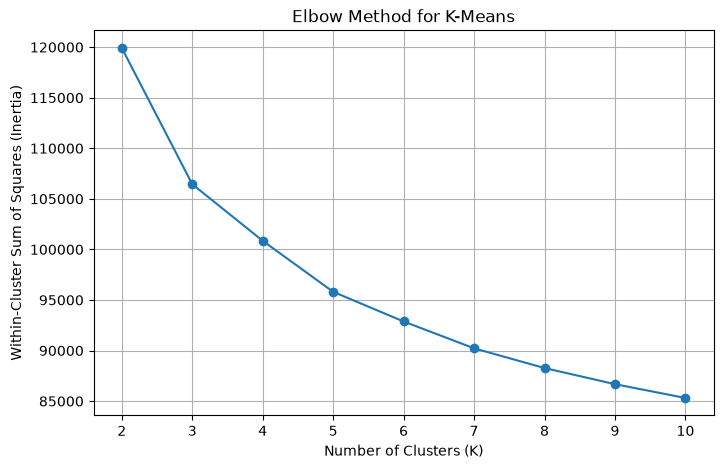

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [9]:
k_values = range(2, 11)
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_behavior_scaled)
    
    score = silhouette_score(
        X_behavior_scaled,
        cluster_labels
    )
    
    silhouette_values.append(score)

print("K values:", list(k_values))
print("Silhouette scores:")
print(silhouette_values)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Silhouette scores:
[0.17754507897033658, 0.169738665254554, 0.1377691847689147, 0.12596543190236761, 0.09265498937511771, 0.0937320636696505, 0.0912722817649362, 0.08863957800235225, 0.08742423058733466]


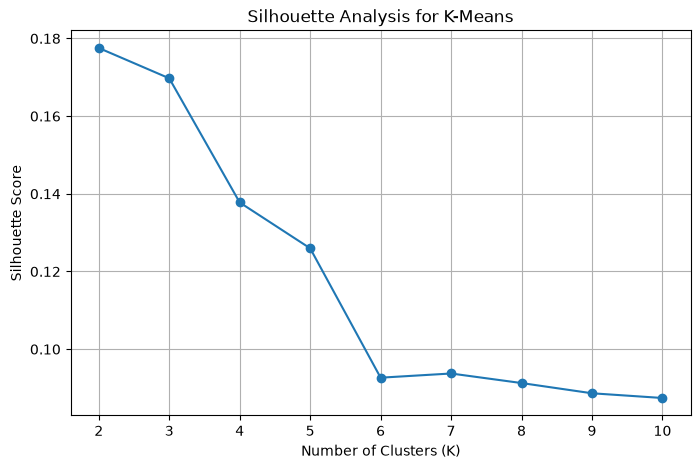

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for K-Means")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [11]:
cluster_comparison = {}

for k in [2, 3]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_behavior_scaled)
    
    cluster_comparison[k] = {
        "model": kmeans,
        "labels": labels
    }

    print(f"\nK = {k}")
    print("-" * 30)
    
    counts = pd.Series(labels).value_counts().sort_index()
    
    print("Cluster sizes:")
    print(counts)
    
    print("\nCluster percentages:")
    print((counts / len(labels) * 100).round(2))


K = 2
------------------------------
Cluster sizes:
0    6348
1    3652
Name: count, dtype: int64

Cluster percentages:
0    63.48
1    36.52
Name: count, dtype: float64

K = 3
------------------------------
Cluster sizes:
0    3880
1    3347
2    2773
Name: count, dtype: int64

Cluster percentages:
0    38.80
1    33.47
2    27.73
Name: count, dtype: float64


In [12]:
for k in [2, 3]:
    
    labels = cluster_comparison[k]["labels"]
    
    temp_df = X_behavior.copy()
    temp_df["cluster"] = labels
    
    profile = temp_df.groupby("cluster")[behavioral_features].mean().round(2)
    
    print(f"\n{'='*60}")
    print(f"BEHAVIORAL PROFILE — K = {k}")
    print(f"{'='*60}")
    print(profile)


BEHAVIORAL PROFILE — K = 2
         sleep_hours  sleep_quality  wake_time_consistency  study_work_hours  \
cluster                                                                        
0               6.09           4.89                   4.39              6.01   
1               7.51           6.87                   6.86              5.62   

         focus_sessions  screen_time_hours  social_media_hours  \
cluster                                                          
0                  3.29               8.18                3.15   
1                  4.66               5.37                1.30   

         notification_interruptions  exercise_minutes  step_count  \
cluster                                                             
0                             57.27             18.30     4690.80   
1                             28.21             46.28     7948.91   

         stress_level  mood_score  energy_level  caffeine_intake  \
cluster                                  

In [13]:
# Detailed K=3 behavioral profile

k = 3

labels = cluster_comparison[k]["labels"]

temp_df = X_behavior.copy()
temp_df["cluster"] = labels

profile_k3 = (
    temp_df
    .groupby("cluster")[behavioral_features]
    .mean()
    .round(2)
)

print("K=3 Behavioral Profile")
print("=" * 80)
print(profile_k3.T)

K=3 Behavioral Profile
cluster                           0        1        2
sleep_hours                    5.75     7.56     6.67
sleep_quality                  4.79     6.92     5.17
wake_time_consistency          4.68     6.97     4.14
study_work_hours               7.73     5.60     3.59
focus_sessions                 4.20     4.69     2.13
screen_time_hours              7.95     5.29     8.30
social_media_hours             2.30     1.24     4.21
notification_interruptions    48.65    27.26    67.28
exercise_minutes              18.80    47.57    19.12
step_count                  4782.81  8075.20  4767.97
stress_level                   7.15     4.13     5.08
mood_score                     4.76     6.95     5.13
energy_level                   4.47     6.80     4.63
caffeine_intake                3.33     1.69     1.83
break_minutes                 36.49    60.60    87.94


In [14]:
print("\nK=3 Cluster Sizes")
print("=" * 40)

cluster_sizes_k3 = pd.Series(labels).value_counts().sort_index()

for cluster, count in cluster_sizes_k3.items():
    percentage = count / len(labels) * 100
    print(
        f"Cluster {cluster}: "
        f"{count} records ({percentage:.2f}%)"
    )


K=3 Cluster Sizes
Cluster 0: 3880 records (38.80%)
Cluster 1: 3347 records (33.47%)
Cluster 2: 2773 records (27.73%)


In [15]:
# Final K-Means model for LifeTwin behavioral profiles

final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

behavioral_clusters = final_kmeans.fit_predict(
    X_behavior_scaled
)

print("Final K-Means completed.")
print("Number of clusters:", final_kmeans.n_clusters)

print("\nCluster sizes:")
print(
    pd.Series(behavioral_clusters)
    .value_counts()
    .sort_index()
)

Final K-Means completed.
Number of clusters: 3

Cluster sizes:
0    3880
1    3347
2    2773
Name: count, dtype: int64


In [16]:
df_behavioral = df.copy()

df_behavioral["behavioral_cluster"] = behavioral_clusters

print(
    df_behavioral[
        ["user_id", "record_date", "behavioral_cluster"]
    ].head(10)
)

  user_id record_date  behavioral_cluster
0    U094  2026-05-13                   0
1    U151  2026-07-14                   2
2    U209  2026-03-29                   2
3    U088  2026-04-10                   1
4    U219  2026-05-21                   1
5    U197  2026-06-08                   0
6    U078  2026-05-25                   0
7    U236  2026-05-17                   0
8    U206  2026-03-08                   2
9    U185  2026-07-06                   0


In [17]:
os.makedirs("../models/behavioral", exist_ok=True)

joblib.dump(
    behavioral_scaler,
    "../models/behavioral/scaler.pkl"
)

joblib.dump(
    final_kmeans,
    "../models/behavioral/kmeans.pkl"
)

print("Behavioral scaler saved:",
      os.path.exists("../models/behavioral/scaler.pkl"))

print("K-Means model saved:",
      os.path.exists("../models/behavioral/kmeans.pkl"))

Behavioral scaler saved: True
K-Means model saved: True


In [18]:
# PCA with all behavioral components

pca_full = PCA()

X_behavior_pca = pca_full.fit_transform(X_behavior_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_variance_df = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": cumulative_variance
})

pca_variance_df

,Component,Explained_Variance,Cumulative_Variance
0,1,0.287268,0.287268
1,2,0.142195,0.429463
2,3,0.078590,0.508053
3,4,0.069498,0.577552
4,5,0.053293,0.630845
5,6,0.049437,0.680282
6,7,0.047317,0.727599
7,8,0.045919,0.773518
8,9,0.042979,0.816497
9,10,0.041359,0.857856


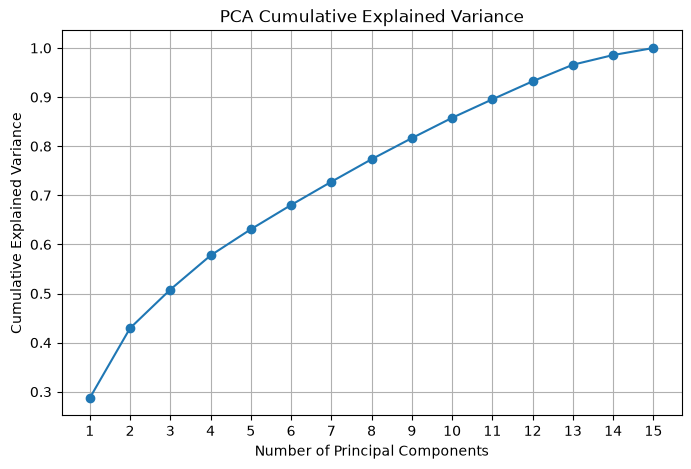

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(1, 16))
plt.grid(True)

plt.show()

In [20]:
# 2D PCA for behavioral visualization

pca_2d = PCA(n_components=2, random_state=42)

X_behavior_pca_2d = pca_2d.fit_transform(X_behavior_scaled)

print("2D PCA shape:", X_behavior_pca_2d.shape)

print("\nExplained variance by component:")
print(pca_2d.explained_variance_ratio_)

print("\nTotal variance explained by 2 components:",
      round(pca_2d.explained_variance_ratio_.sum(), 4))

2D PCA shape: (10000, 2)

Explained variance by component:
[0.28726799 0.14219515]

Total variance explained by 2 components: 0.4295


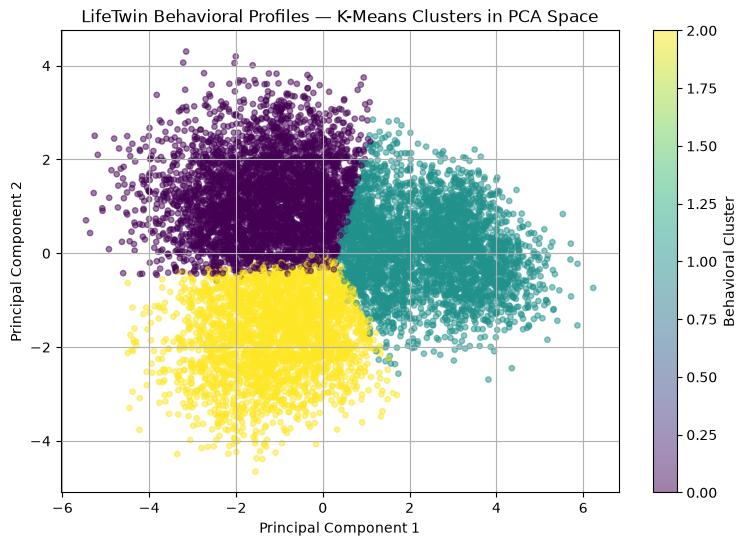

In [21]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_behavior_pca_2d[:, 0],
    X_behavior_pca_2d[:, 1],
    c=behavioral_clusters,
    alpha=0.5,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("LifeTwin Behavioral Profiles — K-Means Clusters in PCA Space")

plt.colorbar(
    scatter,
    label="Behavioral Cluster"
)

plt.grid(True)
plt.show()

In [ ]:
joblib.dump(
    pca_2d,
    "../models/behavioral/pca.pkl"
)

print(
    "PCA model saved:",
    os.path.exists("../models/behavioral/pca.pkl")
)

In [22]:
# Similar-Day kNN model
# Uses the same scaled behavioral representation as K-Means

knn_model = NearestNeighbors(
    n_neighbors=6,
    metric="euclidean"
)

knn_model.fit(X_behavior_scaled)

print("kNN model fitted successfully.")
print("Number of records:", X_behavior_scaled.shape[0])
print("Number of behavioral features:", X_behavior_scaled.shape[1])

kNN model fitted successfully.
Number of records: 10000
Number of behavioral features: 15


In [23]:
query_index = 0

distances, indices = knn_model.kneighbors(
    X_behavior_scaled[query_index].reshape(1, -1)
)

print("Query record:")
print(
    df.loc[
        query_index,
        ["user_id", "record_date"]
    ]
)

print("\nNearest records:")
print(indices[0])

print("\nDistances:")
print(distances[0])

Query record:
user_id              U094
record_date    2026-05-13
Name: 0, dtype: str

Nearest records:
[   0 4654 9815 7559 8677 6983]

Distances:
[0.         2.05083693 2.1088515  2.17516198 2.30849934 2.43965883]


In [24]:
def find_similar_days(query_index, n_similar=5):
    """
    Find the most behaviorally similar historical days
    for a given record.

    Similarity is based only on the 15 behavioral features.
    """

    # +1 because the query record itself will be returned
    distances, indices = knn_model.kneighbors(
        X_behavior_scaled[query_index].reshape(1, -1),
        n_neighbors=n_similar + 1
    )

    similar_indices = indices[0]
    similar_distances = distances[0]

    results = []

    for idx, distance in zip(similar_indices, similar_distances):

        # Skip the query record itself
        if idx == query_index:
            continue

        results.append({
            "record_index": int(idx),
            "user_id": df.loc[idx, "user_id"],
            "record_date": df.loc[idx, "record_date"],
            "distance": round(float(distance), 4),
            "productivity_score": df.loc[idx, "productivity_score"],
            "behavioral_cluster": int(
                behavioral_clusters[idx]
            )
        })

        if len(results) == n_similar:
            break

    return pd.DataFrame(results)

In [25]:
similar_days = find_similar_days(
    query_index=0,
    n_similar=5
)

similar_days

,record_index,user_id,record_date,distance,productivity_score,behavioral_cluster
0,4654,U094,2026-07-03,2.0508,26.4,0
1,9815,U094,2026-05-10,2.1089,37.4,0
2,7559,U094,2026-03-16,2.1752,31.9,0
3,8677,U147,2026-05-07,2.3085,19.5,0
4,6983,U094,2026-06-23,2.4397,26.2,0


In [26]:
joblib.dump(
    knn_model,
    "../models/behavioral/knn_data.pkl"
)

print(
    "kNN model saved:",
    os.path.exists("../models/behavioral/knn_data.pkl")
)

kNN model saved: True


In [27]:
print("Behavioral artifacts:")
print("Scaler:", os.path.exists("../models/behavioral/scaler.pkl"))
print("K-Means:", os.path.exists("../models/behavioral/kmeans.pkl"))
print("PCA:", os.path.exists("../models/behavioral/pca.pkl"))
print("kNN:", os.path.exists("../models/behavioral/knn_data.pkl"))

print("\nRegression model:")
print(
    "Regressor:",
    os.path.exists("../models/regression/best_regressor.pkl")
)

Behavioral artifacts:
Scaler: True
K-Means: True
PCA: False
kNN: True

Regression model:
Regressor: True


In [28]:
# Save the 2D PCA model

os.makedirs("../models/behavioral", exist_ok=True)

joblib.dump(
    pca_2d,
    "../models/behavioral/pca.pkl"
)

print(
    "PCA model saved:",
    os.path.exists("../models/behavioral/pca.pkl")
)

PCA model saved: True


In [29]:
print("Behavioral artifacts:")
print("Scaler:", os.path.exists("../models/behavioral/scaler.pkl"))
print("K-Means:", os.path.exists("../models/behavioral/kmeans.pkl"))
print("PCA:", os.path.exists("../models/behavioral/pca.pkl"))
print("kNN:", os.path.exists("../models/behavioral/knn_data.pkl"))

Behavioral artifacts:
Scaler: True
K-Means: True
PCA: True
kNN: True
